
# Beam search в нейросетевом машинном переводе
Курс «Программирование глубоких нейронных сетей на Python», модуль 09 (Machine Translation)


## §1. Инференс в seq2seq — это задача поиска

Пусть модель перевода (encoder–decoder с вниманием) по входной последовательности $X$ порождает распределение над выходными последовательностями $Y$:

$$P(Y \mid X) = \prod_{t=1}^{L} P(y_t \mid y_1, \dots, y_{t-1},\, X)$$

Задача **инференса** (декодинга) — найти наиболее вероятный перевод, то есть решить задачу MAP-вывода:

$$\hat{Y} = \arg\max_{Y} P(Y \mid X)$$

Такой подход называется **последовательностным выводом** (*sequence-level inference*): важна не вероятность каждого слова по отдельности, а качество всей последовательности целиком.

**Почему нельзя перебрать всё.** Длина словаря $|V|$ в реальных системах — десятки тысяч, длина ответа $L$ — десятки токенов:

$$\text{Число кандидатов} = |V|^{L} = (30\,000)^{20} \approx 10^{92}$$

Это больше, чем атомов во Вселенной. Перебор невозможен → нужен **эвристический поиск**, который за разумное время найдёт *хорошую*, а не обязательно *лучшую* последовательность.

**Интуиция, на которой держится beam search.** Дерево поиска огромно, но «перспективных» ветвей на каждом уровне мало. Если вести поиск в ширину и оставлять на каждом шаге только $k$ лучших гипотез, дерево сожмётся до $O(k \cdot L \cdot |V|)$ узлов — и при достаточном $k$ результат будет близок к оптимуму.



## §2. Жадный декодинг (greedy) — базовый вариант

Самая простая эвристика: на каждом шаге берём слово с максимальной условной вероятностью.

$$y_t = \arg\max_{v \in V} P(v \mid y_1, \dots, y_{t-1}, X)$$

**Свойства:**

* сложность $O(L \cdot |V|)$ — минимум возможных вычислений;
* детерминирован и тривиален в реализации;
* **ошибается локально выбранным решением**: жадность на шаге $t$ не учитывает, что выбор сейчас может «запереть» перевод в дальнейшем.

Аналогия для студентов: идти по лабиринту и на каждом повороте выбирать самую широкую дверь — до цели можно не дойти.

> **Главный тезис урока:** локальный максимум на каждом шаге ≠ глобальный максимум всей последовательности. Именно для борьбы с этим существует beam search.

Ниже — игрушечная модель, на которой мы **руками** покажем провал жадного алгоритма и починим его поиском лучом.



## §3. Алгоритм beam search

**Идея.** Держим в памяти $k$ лучших гипотез (ширина луча, *beam width*). На каждом шаге каждая гипотеза расширяется всеми словами словаря, из всех $k \cdot |V|$ кандидатов отбираются $k$ лучших по накопленной оценке — и цикл повторяется.

**Оценка (score) гипотезы** — сумма логарифмов вероятностей:

$$s(y_1, \dots, y_t) = \sum_{i=1}^{t} \log P(y_i \mid y_1, \dots, y_{i-1}, X) = \log P(y_1, \dots, y_t \mid X)$$

Почему логарифмы, а не произведения:

1. **Численная устойчивость.** Произведение 20 вероятностей порядка $10^{-20}$ теряет точность; сумма логарифмов стабильна.
2. **Монотонность.** Логарифм не меняет порядок: $\arg\max$ по произведению = $\arg\max$ по сумме логарифмов.
3. **Аддитивность.** Продолжение гипотезы = прибавление одного слагаемого.

**Свойства алгоритма (материал для вопросов на семинаре):**

* при $k = 1$ beam search **вырождается в жадный декодинг**;
* при $k \to \infty$ поиск превращается в **точный перебор**;
* $\log P$ **не может вырасти** при добавлении токена (все $\log p \le 0$), поэтому, если лучший из живых лучей уже хуже $k$-й завершённой гипотезы, продолжать бессмысленно — это основа **раннего останова**.

### Псевдокод

```text
ВХОД:  k — ширина луча, Lmax — макс. длина, α — параметр нормировки длины
ВЫХОД: лучшая гипотеза ŷ

B ← { (<start>, 0) }            # живые лучы: (последовательность, оценка log P)
F ← {}                          # завершённые гипотезы (закончились токеном <end>)

для шага t = 1 … Lmax, пока B не пусто:
    C ← {}                      # кандидаты в продолжение
    для каждой гипотезы (y, s) ∈ B:
        вычислить log P(· | y, X)          # один проход декодера
        для каждого v ∈ V с log p(v|y) ≠ -∞:
            если v = <end>:  добавить (y·v, s + log p) в F
            иначе:           добавить (y·v, s + log p) в C
    B ← k гипотез из C с наибольшей оценкой

    # ранний останов (корректен только при α = 0):
    если |F| ≥ k и максимум оценок в B ≤ k-й по величине оценке в F:
        выйти

ŷ ← гипотеза из F с наибольшей оценкой  s / ((5 + L)/6)^α     # нормировка GNMT
```

**Сложность** одного шага: $O(k \cdot |V|)$ вычислений плюс отбор top-$k$. Итого $O(k \cdot L \cdot |V|)$ против $O(L \cdot |V|)$ у greedy, то есть **в $k$ раз дороже**, но на много порядков дешевле полного перебора.



## §4. Численный пример: жадный алгоритм ошибается

Рассмотрим условную «модель перевода» со словарем из 7 токенов. Модель упрощена до цепи Маркова (следующее слово зависит только от предыдущего) — так все вычисления можно проверить калькулятором. Таблица — условные вероятности $P(\text{следующее} \mid \text{текущее})$, каждая строка суммируется в 1:

| текущее ↓ / следующее → | он | мы | встаёт | идём | рано | домой | `<end>` |
|---|---|---|---|---|---|---|---|
| `<start>` | **0.45** | 0.40 | 0.08 | 0.03 | 0.02 | 0.01 | 0.01 |
| он | 0 | 0 | **0.55** | 0.30 | 0.08 | 0.02 | 0.05 |
| мы | 0 | 0 | 0.01 | **0.90** | 0.01 | 0.05 | 0.03 |
| встаёт | 0.05 | 0 | 0 | 0.10 | **0.60** | 0.15 | 0.10 |
| идём | 0.01 | 0 | 0 | 0 | 0.01 | **0.95** | 0.03 |
| рано | 0.05 | 0 | 0.01 | 0.01 | 0 | 0.03 | **0.90** |
| домой | 0.02 | 0 | 0 | 0.01 | 0.02 | 0 | **0.95** |

### Ход жадного алгоритма ($k = 1$)

| Шаг | Лучшее слово | $P$ этого слова | Накопленная оценка |
|---|---|---|---|
| 1 | он | 0.45 | 0.45 |
| 2 | встаёт | 0.55 | 0.45 × 0.55 = **0.2475** |
| 3 | рано | 0.60 | 0.2475 × 0.60 = **0.1485** |
| 4 | `<end>` | 0.90 | 0.1485 × 0.90 = **0.13365** |

**Результат greedy: «он встаёт рано», $P = 0.13365$.**

Теперь ветка, которую greedy отбросил на первом же шаге (второе место, $P = 0.40$):

| Шаг | Слово | $P$ | Накопленная оценка |
|---|---|---|---|
| 1 | мы | 0.40 | 0.40 |
| 2 | идём | 0.90 | 0.40 × 0.90 = **0.3600** |
| 3 | домой | 0.95 | 0.36 × 0.95 = **0.3420** |
| 4 | `<end>` | 0.95 | 0.342 × 0.95 = **0.3249** |

**Лучший перевод: «мы идём домой», $P = 0.3249$ — в 2.4 раза вероятнее!**

> Жадный алгоритм «видел» эту ветку (на шаге 1 она шла второй с $P = 0.40$ против $0.45$), но вернуться к ней не может. Beam search с $k = 2$ её находит — §5 и исполняемые ячейки ниже.



## §5. Тот же пример с beam search ($k = 2$)

На каждом шаге расширяем обе живые гипотезы и оставляем 2 лучших.

**Шаг 1.** Кандидаты: он 0.45, мы 0.40, встаёт 0.08, идём 0.03, рано 0.02, домой 0.01, `<end>` 0.01 → **в луч: «он» (0.45), «мы» (0.40)**.

**Шаг 2.** Расширяем обе гипотезы:

| Родитель | Слово | Оценка | Место |
|---|---|---|---|
| мы | идём | 0.40 × 0.90 = **0.3600** | 1 ✅ в луч |
| он | встаёт | 0.45 × 0.55 = **0.2475** | 2 ✅ в луч |
| он | идём | 0.45 × 0.30 = 0.1350 | 3 ❌ отсечена |
| он | рано | 0.45 × 0.08 = 0.0360 | отсечена |
| он | `<end>` | 0.45 × 0.05 = 0.0225 | завершена, но слабая |
| мы | домой | 0.40 × 0.05 = 0.0200 | отсечена |

**В луч: «мы идём» (0.3600) и «он встаёт» (0.2475).** Жадный алгоритм уже ушёл по ветке «он встаёт», beam search продолжает держать обе.

**Шаг 3:**

| Родитель | Слово | Оценка | Место |
|---|---|---|---|
| мы идём | домой | 0.36 × 0.95 = **0.3420** | 1 ✅ |
| он встаёт | рано | 0.2475 × 0.60 = **0.1485** | 2 ✅ |
| он встаёт | домой | 0.2475 × 0.15 = 0.0371 | 3 ❌ отсечена |
| он встаёт | `<end>` | 0.2475 × 0.10 = 0.0248 | завершена |

**Шаг 4:**

| Родитель | Слово | Оценка | Статус |
|---|---|---|---|
| мы идём домой | `<end>` | 0.342 × 0.95 = **0.3249** | ✅ завершена, **лучшая** |
| он встаёт рано | `<end>` | 0.1485 × 0.90 = **0.13365** | ✅ завершена, вторая |

**Итог: beam search ($k = 2$) находит «мы идём домой» с $P = 0.3249$, greedy — «он встаёт рано» с $P = 0.13365$.**

Ниже код **воспроизводит этот расчёт по шагам**: печатает журнал расширений, сравнивает greedy / beam / точный перебор и рисует дерево поиска.


In [1]:
# -*- coding: utf-8 -*-
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time

%matplotlib inline
np.set_printoptions(suppress=True)
print("Готово: numpy", np.__version__, "| pandas", pd.__version__)

Готово: numpy 1.24.3 | pandas 1.5.3


In [2]:
# =====================================================================
# Игрушечная "модель перевода": цепь Маркова со словарём из 7 токенов.
# Это не нейросеть, но интерфейс у неё ровно такой же, как у декодера:
# по уже сгенерированной последовательности она выдаёт распределение
# следующего токена
# =====================================================================

VOCAB = ['он', 'мы', 'встаёт', 'идём', 'рано', 'домой', '<end>']
START = '<start>'
IDX = {t: i for i, t in enumerate(VOCAB)}
END_IDX = IDX['<end>']

TRANSITIONS = {
    '<start>': {'он': .45, 'мы': .40, 'встаёт': .08, 'идём': .03, 'рано': .02, 'домой': .01, '<end>': .01},
    'он':      {'встаёт': .55, 'идём': .30, 'рано': .08, '<end>': .05, 'домой': .02},
    'мы':      {'идём': .90, 'домой': .05, '<end>': .03, 'рано': .01, 'встаёт': .01},
    'встаёт':  {'рано': .60, 'домой': .15, 'идём': .10, '<end>': .10, 'он': .05},
    'идём':    {'домой': .95, '<end>': .03, 'рано': .01, 'он': .01},
    'рано':    {'<end>': .90, 'он': .05, 'домой': .03, 'идём': .01, 'встаёт': .01},
    'домой':   {'<end>': .95, 'рано': .02, 'он': .02, 'идём': .01},
    '<end>':   {},                      # терминальное состояние
}

# Проверка: каждая строка вероятностей должна суммироваться в 1
# (у терминального состояния <end> исходящих переходов нет)
for state, row in TRANSITIONS.items():
    if row:
        assert abs(sum(row.values()) - 1.0) < 1e-9, (state, sum(row.values()))
print("Строки вероятностей суммируются в 1 — модель корректна.")


def transitions_table(vocab=VOCAB, transitions=TRANSITIONS):
    """Таблица вероятностей для показа студентам."""
    states = [START] + vocab
    df = pd.DataFrame(index=states, columns=vocab, dtype=float)
    for s in states:
        for v in vocab:
            df.loc[s, v] = transitions[s].get(v, 0.0)
    return df


# Подсветка: в каждой строке зелёным отмечен argmax - то, что выбрал бы greedy
transitions_table().style.format('{:.2f}').highlight_max(axis=1, color='lightgreen')

Строки вероятностей суммируются в 1 — модель корректна.


,он,мы,встаёт,идём,рано,домой,
,0.45,0.40,0.08,0.03,0.02,0.01,0.01
он,0.00,0.00,0.55,0.30,0.08,0.02,0.05
мы,0.00,0.00,0.01,0.90,0.01,0.05,0.03
встаёт,0.05,0.00,0.00,0.10,0.60,0.15,0.10
идём,0.01,0.00,0.00,0.00,0.01,0.95,0.03
рано,0.05,0.00,0.01,0.01,0.00,0.03,0.90
домой,0.02,0.00,0.00,0.01,0.02,0.00,0.95
,0.00,0.00,0.00,0.00,0.00,0.00,0.00



### Интерфейс «чёрного ящика»: `next_log_probs`

Весь поиск отделён от модели одной функцией:

```python
next_log_probs(prefix) -> np.ndarray   # log P(следующий токен | уже сгенерированное), размер |V|
```

* вход — список **идентификаторов** уже сгенерированных токенов (без `<start>`);
* выход — вектор логарифмов вероятностей длины $|V|$; невозможные переходы кодируются как $-\infty$.

Жадный алгоритм, beam search, точный перебор и сэмплирование используют **одну и ту же** функцию — различается только стратегия выбора. Поэтому beam search так легко подключить к любой обученной модели.


In [4]:
def _fmt(seq, vocab=VOCAB):
    """Последовательность id -> строка для журнала и печати."""
    return ' '.join(vocab[i] for i in seq)


def make_log_probs_fn(vocab=VOCAB, transitions=TRANSITIONS):
    """Оборачивает таблицу вероятностей в интерфейс next_log_probs(prefix)."""
    def next_log_probs(prefix):
        state = START if len(prefix) == 0 else vocab[prefix[-1]]
        row = transitions[state]
        return np.array([np.log(row[v]) if row.get(v, 0.0) > 0 else -np.inf
                         for v in vocab])
    return next_log_probs


def beam_search(next_log_probs, k=3, max_len=10, alpha=0.0,
                end_idx=END_IDX, vocab_size=len(VOCAB), trace=False):
    """Поиск лучом (beam search).

    next_log_probs(prefix) -> np.ndarray (|V|,): log P(следующий токен | префикс)
    k       - ширина луча; k=1 эквивалентен greedy-декодингу
    max_len - макс. число генерируемых токенов (включая <end>)
    alpha   - нормировка длины GNMT: logP / ((5 + L)/6)**alpha; 0 - выключена
    trace   - True -> журнал расширений по шагам (pandas DataFrame)

    Возвращает (results, trace_df):
    results = [(токены, сырой logP, итоговая оценка), ...] по убыванию оценки.
    """
    def final_score(seq, raw):
        if alpha == 0:
            return raw
        return raw / (((5.0 + len(seq)) / 6.0) ** alpha)

    beams = [([], 0.0)]          # живые лучы: (токены, накопленный log P)
    finished = []                # завершённые гипотезы (закончились <end>)
    rows = []                    # журнал для trace

    for step in range(1, max_len + 1):
        if not beams:
            break

        # --- 1. расширяем каждый живой луч всем словарём -------------
        expanded = []            # (родительский префикс, токен, оценка, log p)
        for seq, s in beams:
            lp = next_log_probs(seq)
            for v in range(vocab_size):
                if np.isfinite(lp[v]):
                    expanded.append((seq, v, s + lp[v], lp[v]))

        # --- 2. токен <end> завершает гипотезу, остальное - кандидаты --
        cont = [(seq, v, sc, lg) for seq, v, sc, lg in expanded if v != end_idx]
        for seq, v, sc, _ in expanded:
            if v == end_idx:
                finished.append((seq + [v], sc))

        # --- 3. оставляем k лучших продолжений -----------------------
        cont.sort(key=lambda x: -x[2])
        best = cont[:k]
        beams = [(seq + [v], sc) for seq, v, sc, _ in best]

        # --- 4. журнал расширений (нужен только для разбора на занятии)
        if trace:
            kept = {(tuple(seq), v) for seq, v, _, _ in best}
            for seq, v, sc, lg in expanded:
                if v == end_idx:
                    status = 'завершена'
                elif (tuple(seq), v) in kept:
                    status = 'в луче'
                else:
                    status = 'отсечена'
                rows.append({'шаг': step,
                             'расширение': _fmt(seq + [v]),
                             'log p': round(float(lg), 4),
                             'оценка': round(float(sc), 4),
                             'статус': status})

        # --- 5. ранний останов ---------------------------------------
        # log P не растёт при добавлении токенов, поэтому, если все живые
        # лучы уже хуже k-й завершённой гипотезы, улучшить результат нельзя.
        # (При alpha > 0 оценка перестаёт быть монотонной - см. §6.)
        if alpha == 0 and len(finished) >= k and beams:
            top_fin = sorted((sc for _, sc in finished), reverse=True)
            if beams[0][1] <= top_fin[k - 1]:
                break

    candidates = finished if finished else beams
    results = sorted(((seq, raw, final_score(seq, raw))
                      for seq, raw in candidates), key=lambda r: -r[2])
    return results, (pd.DataFrame(rows) if trace else None)


def greedy_search(next_log_probs, max_len=10, end_idx=END_IDX, vocab_size=len(VOCAB)):
    """Жадный декодинг: на каждом шаге argmax. Эквивалент beam_search(k=1)."""
    seq, s = [], 0.0
    for _ in range(max_len):
        lp = next_log_probs(seq)
        v = int(np.argmax(lp))
        s += lp[v]
        seq.append(v)
        if v == end_idx:
            break
    return seq, s


def exact_search(next_log_probs, max_len=6, end_idx=END_IDX, vocab_size=len(VOCAB)):
    """Точный перебор (контроль): обходит всё дерево, возвращает лучшую гипотезу.
    Применим только в игрушечных размерах - на реальном словаре это |V|^L."""
    best = None

    def dfs(seq, s):
        nonlocal best
        if seq and seq[-1] == end_idx:
            if best is None or s > best[1]:
                best = (seq[:], s)
            return
        if len(seq) >= max_len:
            return
        lp = next_log_probs(seq)
        for v in range(vocab_size):
            if np.isfinite(lp[v]):
                dfs(seq + [v], s + lp[v])

    dfs([], 0.0)
    return best


### Запуск: greedy против beam search против точного перебора


In [5]:
model = make_log_probs_fn()

# --- 1. Жадный декодинг ------------------------------------------------
g_seq, g_logp = greedy_search(model)
print("GREEDY  :", _fmt(g_seq), f"  log P = {g_logp:.4f}   P = {np.exp(g_logp):.5f}")

# --- 2. Beam search, k = 2 --------------------------------------------
b_results, trace_df = beam_search(model, k=2, max_len=6, trace=True)
b_seq, b_logp, b_score = b_results[0]
print("BEAM k=2:", _fmt(b_seq), f"  log P = {b_logp:.4f}   P = {np.exp(b_logp):.5f}")

# --- 3. Точный перебор (контроль) --------------------------------------
e_seq, e_logp = exact_search(model, max_len=6)
print("EXACT   :", _fmt(e_seq), f"  log P = {e_logp:.4f}   P = {np.exp(e_logp):.5f}")

print()
print(f"Жадный алгоритм потерял в {np.exp(e_logp - g_logp):.1f} раза вероятности; "
      f"beam search (k=2) нашёл оптимум: {np.isclose(b_logp, e_logp)}")

GREEDY  : он встаёт рано <end>   log P = -2.0125   P = 0.13365
BEAM k=2: мы идём домой <end>   log P = -1.1242   P = 0.32490
EXACT   : мы идём домой <end>   log P = -1.1242   P = 0.32490

Жадный алгоритм потерял в 2.4 раза вероятности; beam search (k=2) нашёл оптимум: True


In [6]:
# Журнал расширений beam search (k=2): что алгоритм рассматривал и что отбросил
trace_df

,шаг,расширение,log p,оценка,статус
0,1,он,-0.7985,-0.7985,в луче
1,1,мы,-0.9163,-0.9163,в луче
2,1,встаёт,-2.5257,-2.5257,отсечена
3,1,идём,-3.5066,-3.5066,отсечена
4,1,рано,-3.9120,-3.9120,отсечена
5,1,домой,-4.6052,-4.6052,отсечена
6,1,<end>,-4.6052,-4.6052,завершена
7,2,он встаёт,-0.5978,-1.3963,в луче
8,2,он идём,-1.2040,-2.0025,отсечена
9,2,он рано,-2.5257,-3.3242,отсечена


In [7]:
# Сводная таблица: все методы на одной модели
rows = []
for name, k in [('greedy (k=1)', 1), ('beam k=2', 2), ('beam k=3', 3),
                ('beam k=5', 5)]:
    res = beam_search(model, k=k, max_len=6)[0]
    rows.append({
        'метод': name,
        'перевод': _fmt(res[0][0]),
        'log P': round(res[0][1], 4),
        'P': f"{np.exp(res[0][1]):.5f}",
        'результат совпал с точным перебором': bool(np.isclose(res[0][1], e_logp)),
    })
rows.append({
    'метод': 'точный перебор',
    'перевод': _fmt(e_seq),
    'log P': round(e_logp, 4),
    'P': f"{np.exp(e_logp):.5f}",
    'результат совпал с точным перебором': True,
})
pd.DataFrame(rows)

,метод,перевод,log P,P,результат совпал с точным перебором
0,greedy (k=1),он встаёт рано <end>,-2.0125,0.13365,False
1,beam k=2,мы идём домой <end>,-1.1242,0.32490,True
2,beam k=3,мы идём домой <end>,-1.1242,0.32490,True
3,beam k=5,мы идём домой <end>,-1.1242,0.32490,True
4,точный перебор,мы идём домой <end>,-1.1242,0.32490,True


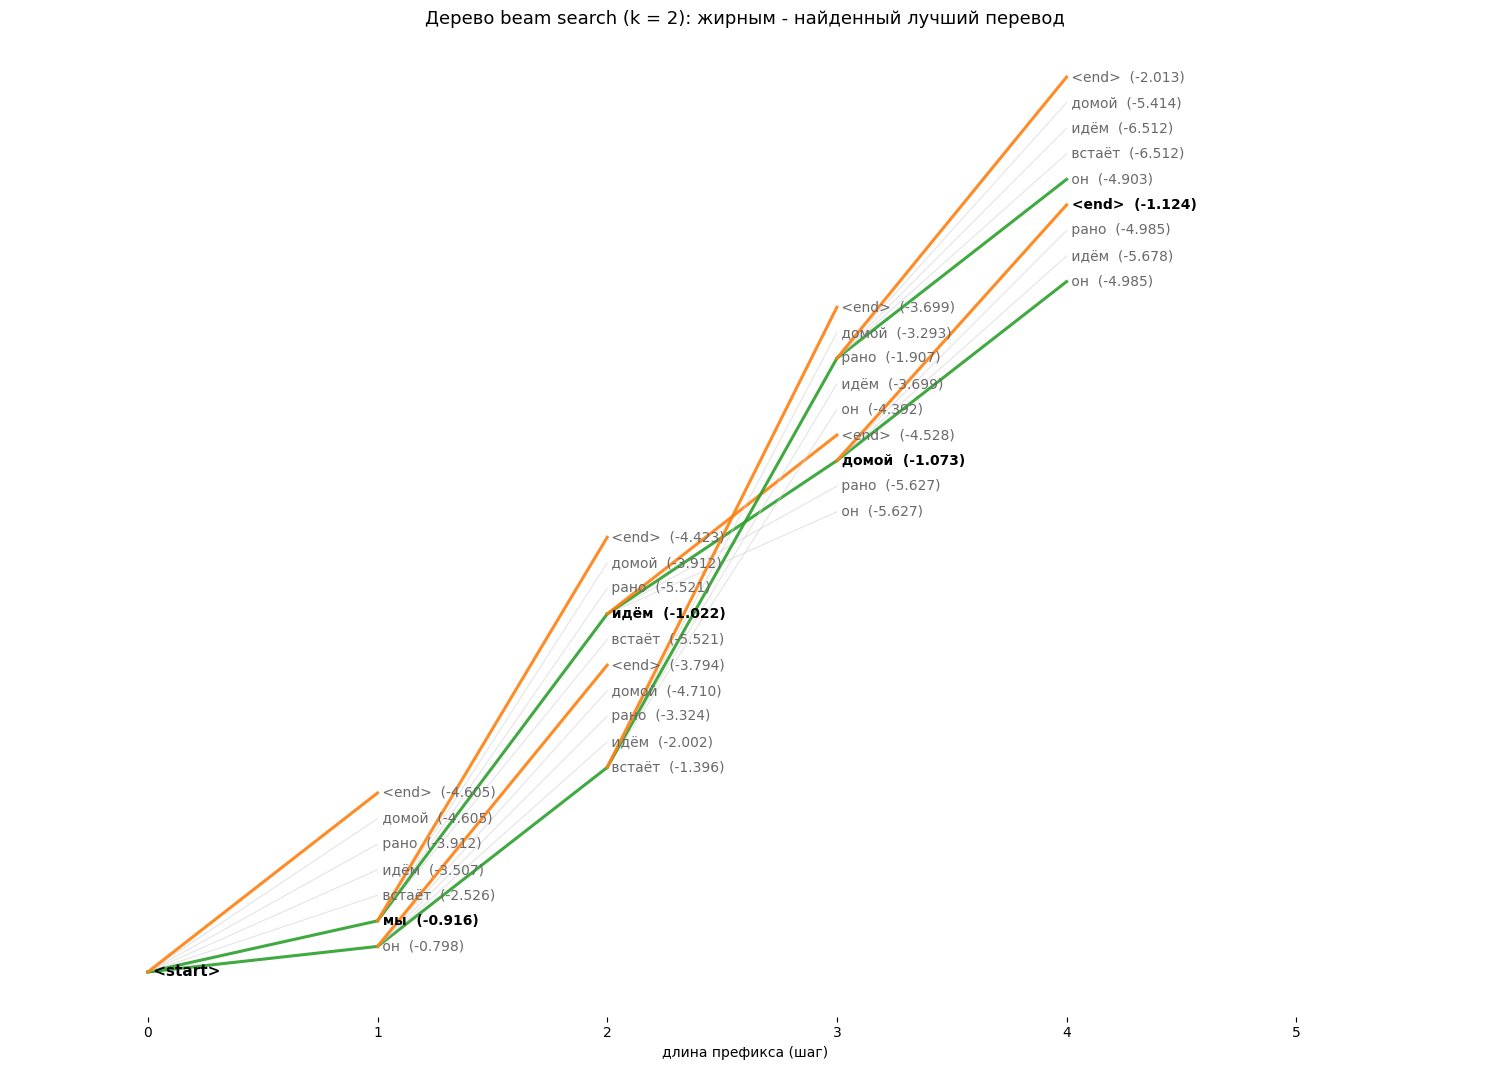

In [8]:
# Дерево поиска: зелёные рёбра - путь, выбранный алгоритмом; серые - отсечены;
# оранжевые - гипотеза завершилась токеном <end>. Числа - накопленные log P.
def plot_beam_tree(results, trace_df, vocab=VOCAB):
    edges = []   # (родитель, потомок, статус, оценка)
    for _, r in trace_df.iterrows():
        seq = tuple(vocab.index(t) for t in r['расширение'].split())
        edges.append((seq[:-1], seq, r['статус'], r['оценка']))

    best = tuple(results[0][0])

    # координаты: x = длина префикса, y = порядок появления в журнале
    y_pos = {(): 0.0}
    y = 1.0
    for _, child, _, _ in edges:
        if child not in y_pos:
            y_pos[child] = y
            y += 1.0

    colors = {'в луче': 'tab:green', 'отсечена': 'lightgray', 'завершена': 'tab:orange'}
    fig, ax = plt.subplots(figsize=(15, max(6.0, 0.30 * y)))

    for parent, child, status, score in edges:
        ax.plot([len(parent), len(child)], [y_pos[parent], y_pos[child]],
                color=colors[status], lw=2.2 if status != 'отсечена' else 0.8,
                alpha=0.9 if status != 'отсечена' else 0.6, zorder=1)

    for _, child, status, score in edges:
        in_best = best[:len(child)] == child
        ax.text(len(child), y_pos[child],
                f" {vocab[child[-1]]}  ({score:.3f})",
                fontsize=10, va='center', zorder=3,
                fontweight='bold' if in_best else 'normal',
                color='black' if in_best else 'dimgray')

    ax.text(0, 0, " <start> ", fontsize=11, va='center',
            fontweight='bold', color='black')
    ax.set_title("Дерево beam search (k = 2): жирным - найденный лучший перевод",
                 fontsize=13)
    ax.set_xlabel("длина префикса (шаг)")
    ax.set_yticks([])
    ax.set_xlim(-0.6, max(len(c) for _, c, _, _ in edges) + 1.8)
    for sp in ax.spines.values():
        sp.set_visible(False)
    plt.tight_layout()
    plt.show()

plot_beam_tree(b_results, trace_df)


### Что мы увидели на графике

1. **Корень** — `<start>`; от каждой живой вершины отходят рёбра ко *всем* словам словаря (серые — отсечённые: к ним поиск не возвращается никогда).
2. **Зелёная траектория** — путь, выбранный алгоритмом: `мы → идём → домой → <end>`.
3. Жадный алгоритм прошёл бы только по ветке `он → встаёт → ...` (первый ребёнок корня) и зелёный путь не увидел бы вовсе.
4. **Оранжевые рёбра** — гипотезы, завершённые `<end>`: они не расширяются дальше и попадают в финальный рейтинг.
5. Накопленные `log P` вглубь дерева только убывают — из этого следует правило раннего останова.

Вопрос студентам: *сколько узлов перебирает алгоритм при $k = 2$, $L = 6$, а сколько полный перебор?* (Ответ: $\approx k \cdot L \cdot |V|$ против $|V|^L$.)



## §6. Смещение к коротким ответам и нормировка длины (length normalization)

**Проблема.** Оценка $s = \log P(y_1, \dots, y_L)$ — сумма отрицательных слагаемых: чем длиннее гипотеза, тем меньше её оценка. И greedy, и beam начинают **систематически предпочитать короткие ответы**: если вероятность `<end>` заметна, обрывать перевод часто «выгоднее», чем добавлять ещё одно слово.

**Решение — нормировка длины.** В работе о Google NMT (Wu et al., 2016) оценку делят на растущую с длиной функцию:

$$s_{\text{GNMT}}(Y) = \frac{\log P(Y \mid X)}{\left(\frac{5 + L}{5 + 1}\right)^{\alpha}}, \qquad L = |Y|$$

* $\alpha = 0$ — исходная оценка (сырой $\log P$): предвзятость к коротким сохраняется;
* $\alpha = 1$ — примерно среднее по токенам (деление на длину);
* $\alpha \approx 0.6\text{–}0.7$ — типичные значения для NMT, подбираются по BLEU на валидации.

Простейшая альтернатива — среднее логарифмов $s = \frac{1}{L}\sum_t \log P(y_t \mid \dots)$; GNMT-форма гибче.

**Демонстрация смены ранжирования.** Две гипотезы одной модели: короткая вероятнее, но длинная плотнее по вероятности «на токен»:


In [9]:
# Гипотезы: короткая имеет большую сырую вероятность, длинная - бо́льшую "плотность"
hyp = pd.DataFrame({
    'гипотеза': ['короткая', 'длинная'],
    'P': [0.10, 0.06],
    'L': [2, 6],
})
hyp['log P'] = np.log(hyp['P'])


def gnmt_score(log_p, L, alpha):
    """Оценка GNMT: logP / ((5 + L)/6)**alpha."""
    return log_p / (((5.0 + L) / 6.0) ** alpha)


for a in [0.0, 0.4, 0.7, 1.0]:
    hyp[f'alpha={a}'] = [gnmt_score(lp, L, a) for lp, L in zip(hyp['log P'], hyp['L'])]
hyp['среднее logP / токен'] = hyp['log P'] / hyp['L']

score_cols = [c for c in hyp.columns if c not in ('гипотеза', 'P', 'L', 'log P')]
hyp_display = hyp.copy()
for c in score_cols + ['log P']:
    hyp_display[c] = hyp_display[c].round(3)

print("Зелёным - победитель рейтинга при каждой оценке:")
hyp_display.style.highlight_max(axis=0, subset=score_cols, color='lightgreen')

Зелёным - победитель рейтинга при каждой оценке:


,гипотеза,P,L,log P,alpha=0.0,alpha=0.4,alpha=0.7,alpha=1.0,среднее logP / токен
0,короткая,0.100000,2,-2.303000,-2.303000,-2.165000,-2.067000,-1.974000,-1.151000
1,длинная,0.060000,6,-2.813000,-2.813000,-2.208000,-1.841000,-1.535000,-0.469000



**Вывод из таблицы:** при $\alpha = 0$ побеждает короткая гипотеза, при $\alpha = 0.7$ — длинная. Нормировка длины не украшение, а способ убрать систематическое смещение (*bias*) алгоритма.

> ⚠️ **Побочный эффект.** Ранний останов (§3) опирается на то, что сырой $\log P$ не растёт. После включения нормировки оценка перестаёт быть монотонной, поэтому при $\alpha > 0$ ранний останов становится приближением: лучи прогоняют до `max_len` или до момента, когда набралось достаточно завершённых гипотез. Отличный вопрос для проверки понимания (см. контрольные вопросы).



## §7. Сравнение стратегий декодинга

| Стратегия | Что делает | Плюсы | Минусы | Где применяют |
|---|---|---|---|---|
| **Greedy** | argmax на каждом шаге | быстро, просто, детерминированно | локальные решения, повторы | базовый вариант |
| **Beam search** | $k$ лучших гипотез | близко к MAP, детерминированно | дороже в $k$ раз, смещение к коротким, «скучные» тексты | **машинный перевод**, ASR, суммаризация, QA |
| **Сэмплирование** | случайный выбор по распределению | разнообразие, «живость» | недетерминировано, риск ошибок | чат-боты, генерация текста |
| **Top-k / top-p** | сэмплирование из $k$ самых вероятных / до кумулятивной вероятности $p$ | компромисс качество/разнообразие | есть гиперпараметры | языковые модели (GPT и др.) |
| **Temperature** | сглаживание/заострение распределения | простая регулировка «креативности» | не гарантирует качество | языковые модели |

**Практические рекомендации для NMT:**

* $k = 3\text{–}10$, типично $k = 4$ или $5$. Рост $k$ даёт убывающую отдачу: почти весь выигрыш — от $k = 1 \to 3$.
* Обязательно задавать `max_len` (часто $\approx$ длина входа × 1.5–2) и нормировку длины.
* **Цена увеличения $k$:** время растёт линейно ($O(k \cdot L \cdot |V|)$). При батчевом инференсе выигрыш ещё меньше — потому что батч «расширяется» в $k$ раз: `batch_size` последовательностей превращается в `batch_size × k`. Замерить — задача 5.
* Beam search чувствителен к мелким изменениям модели: при малейшем сдвиге весов может резко «перескакивать» на другой перевод
* В современных **LLM** beam search почти не используется: там важна вариативность, поэтому берут greedy или top-p сэмплирование. Beam search остаётся инструментом **вход-ориентированных** задач (перевод, распознавание речи), где нужен один лучший результат.
